### 연도별 치이카와 영상 게시 추이

이번 그래프의 목적은 시청 반응이 아니라, **연도별로 영상이 얼마나 늘었는지**를 보는 것이다.

- 영상 수: 한국 시간 기준 그 해에 게시된 고유 `post_id`
- 채널 수: 그 해에 영상을 1개 이상 올린 고유 `account_id`. 누적 채널 수도, 그 해 처음 나타난 채널 수도 아니다.
- 데이터: `youtube_analysis_video_table.csv`. 검색으로 모은 뒤 명칭이 확인된 영상이다.

2022~2025년은 1월부터 12월까지다. 2026년은 데이터에 있는 게시일까지만 포함한다. 빗금이 그 해다. 막대 높이는 같은 행끼리만 비교한다.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_rows", 100)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path(r"C:/Users/user/DATA_MKT_260920/data.project/KDT_Integral_Data_Project/02_csv/01_youtube")
VIDEO_CSV = (
    ROOT / "1. videos" / "02. cleaning" / "02. 3NF_&_칼럼명_통합" / "youtube_analysis_video_table.csv"
)

video = pd.read_csv(VIDEO_CSV, encoding="utf-8-sig").copy()
video["created_at_kst"] = pd.to_datetime(video["created_at"], utc=True).dt.tz_convert("Asia/Seoul")
video["year"] = video["created_at_kst"].dt.year

asof = video["created_at_kst"].max()
print(f"행 {len(video):,} | 영상 {video['post_id'].nunique():,} | 채널 {video['account_id'].nunique():,}")
print(f"post_id 중복 {int(video['post_id'].duplicated().sum())}")
print(f"게시 시각 {video['created_at_kst'].min()} ~ {asof}")
print(
    "결측 | "
    + ", ".join(f"{col} {int(video[col].isna().sum())}" for col in ["post_title", "description", "view_count", "like_count", "comment_count"])
)


Duplicate key in file WindowsPath('C:/Users/user/AppData/Local/Programs/Python/Python311/Lib/site-packages/matplotlib/mpl-data/matplotlibrc'), line 269 ('font.family:  sans-serif')


행 13,383 | 영상 13,383 | 채널 5,668
post_id 중복 0
게시 시각 2022-01-03 16:04:09+09:00 ~ 2026-10-26 19:00:08+09:00
결측 | post_title 0, description 6557, view_count 0, like_count 0, comment_count 0


게시 시각 2022-01-03 ~ 2026-10-26
2022~2025년은 1~12월. 2026년은 데이터에 있는 게시일까지


,영상수,채널수,채널당_영상수
year,,,
2022,1945,773,2.52
2023,2834,1180,2.40
2024,2710,1306,2.08
2025,3012,1711,1.76
2026,2882,1397,2.06


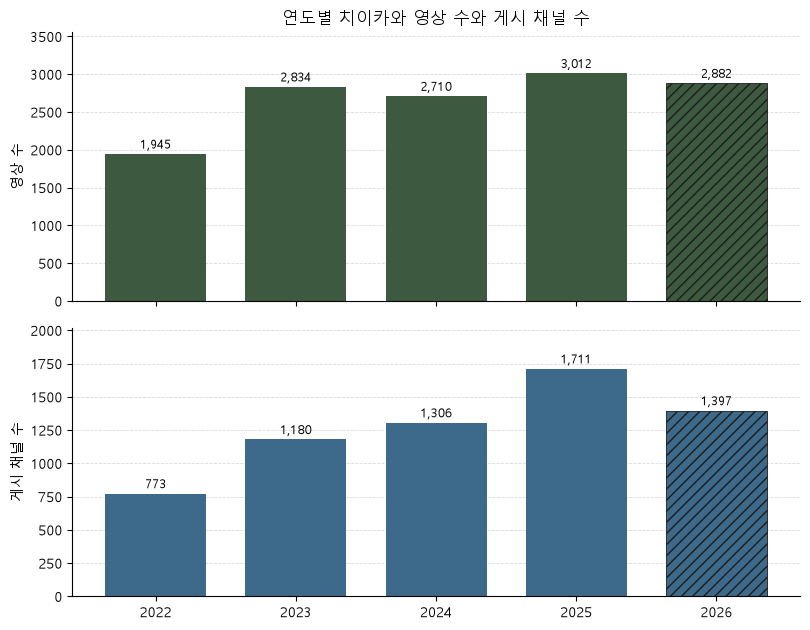

In [2]:
yearly = (
    video.groupby("year", as_index=True)
    .agg(영상수=("post_id", "nunique"), 채널수=("account_id", "nunique"))
    .sort_index()
)
yearly["채널당_영상수"] = (yearly["영상수"] / yearly["채널수"]).round(2)

latest_year = int(asof.year)
partial_years = set()
if not (asof.month == 12 and asof.day == 31):
    partial_years.add(latest_year)

print(f"게시 시각 {video['created_at_kst'].min().date()} ~ {asof.date()}")
print("2022~2025년은 1~12월. 2026년은 데이터에 있는 게시일까지")
display(yearly)

years = yearly.index.astype(int).tolist()
x = list(range(len(years)))
metrics = [
    ("영상수", "영상 수", "#3d5a40"),
    ("채널수", "게시 채널 수", "#3d6a8a"),
]

fig, axes = plt.subplots(2, 1, figsize=(8.2, 6.4), sharex=True)
for ax, (colname, ylabel, color) in zip(axes, metrics):
    bars = ax.bar(x, yearly[colname].to_numpy(), color=color, width=0.72, zorder=2)
    for i, year in enumerate(years):
        if year in partial_years:
            bars[i].set_hatch("///")
            bars[i].set_edgecolor("#1c1c1c")
            bars[i].set_linewidth(0.6)
    ax.bar_label(bars, labels=[f"{int(v):,}" for v in yearly[colname]], padding=2, fontsize=9)
    ax.set_ylabel(ylabel)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.45)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(0, yearly[colname].max() * 1.18)

axes[0].set_title("연도별 치이카와 영상 수와 게시 채널 수")
axes[1].set_xticks(x)
axes[1].set_xticklabels([str(year) for year in years])
fig.tight_layout()
plt.show()


### 읽는 법

2022~2025년 막대는 1월부터 12월까지다. 2026년 빗금은 데이터에 있는 게시일까지이고, 1~12월이 아니다. 발표에서는 이 해를 수집일 기준으로 보여 준다고 말하면 된다. 2025년 전체와 높이를 완성된 연도끼리의 증감으로 읽지 않는다.

2022~2025년에는 영상 수보다 게시 채널 수가 더 꾸준히 늘고, 채널당 영상 수는 줄어든다. 이 구간의 게시량 증가는 채널이 더 자주 올려서가 아니라, 영상을 올리는 채널이 늘어서 생긴 쪽에 가깝다. 2024년은 채널 수가 늘었는데 영상 수는 줄었다.

### 이후 분석에서 피할 점

1. 게시량을 관심도로 두지 않는다. 이 그래프는 올라온 영상 수다. 관심은 조회와 반응으로 따로 봐야 하고, 둘은 어긋날 수 있다.
2. 업로드 연도로 `view_count`를 합쳐 그 해의 관심이라고 말하지 않는다. 조회수는 수집 시점까지의 누적이고, 2022년 영상은 노출 기간이 길며 2026년 영상은 짧다. 연도를 비교하려면 게시 후 같은 기간의 조회(예: 30일)나, 나이가 비슷한 영상만 쓰는 편이 맞다.
3. 채널 수를 누적 규모나 신규 채널 수로 읽지 않는다. 여기서는 그 해에 1개 이상 올린 채널이다. 여러 해에 올린 채널은 해마다 다시 센다.
4. 이 표는 유튜브의 치이카와 영상 전부가 아니다. 검색어는 `치이카와`이고, `regionCode=KR`, `relevanceLanguage=ko`, `order=relevance`로 월 단위 검색한 뒤 제목·설명·태그에서 명칭이 확인된 영상이다. `search.list`는 검색 한 번당 약 500건이 상한이다. 월별 상위가 400~447건이라 성수월은 상한에 가깝고, 그 달 영상이 더 있었다면 최근 수치는 과소다.
5. 정제 단계에서 좋아요·댓글 결측을 0으로 채웠다. 지금 0에는 실제 0과 결측 대체가 섞여 있다. 반응 지표의 평균에 그대로 넣기 전에, 수집 원본의 결측과 구분할 수 있는지 확인이 필요하다. 설명 결측은 6,557건이라, 설명 문구로 유형을 나누면 절반 가까이가 비어 있다.


### 제목·설명 분류

조회수는 수집일 하나의 누적이라 연도로 비교하지 않는다. 아래는 제목과 설명에 글이 있는지로 영상을 갈라둔다.

- A 작품·캐릭터 감상·장면 공유: 극장, 영화, 애니, 본편, 장면, 예고편, 스포, 전편
- B 개인 상품 관심·소비·소유·사용: 키링, 피규어, 가챠, 굿즈, 하울, 언박, 개봉, 인형, 팝업, 카페, 다이소, 쿠지, 제일복권. 코드북에 오프라인이 없어서 팝업·카페 방문은 여기에 둔다.
- C 팬 창작·꾸미기·제작물 공유: 인형계, 상황극, 그림, 그리기, 더빙(제목만), 만들기, 꾸미기, 따라하기. 인형계는 상품 소장(B)이 아니다.
- D 상품·거래·협찬·이벤트 안내: 판매, 양도, 나눔, 공구, 중고, 협찬, 유료광고, 이벤트, 추첨, 입고, 출시
- E 다른 인물·대상·팬덤 관련: 콜라보, 산리오, 포켓몬, 짱구, 도라에몽, 귀멸, 주술회전, 농담곰, 다마고치, 유니클로처럼 목록에 있는 이름. 목록 밖의 팬덤은 여기에 안 들어갈 수 있다.
- F 콘텐츠 정보·번역·독자 교류: 번역, 해석, 한글자막, 세계관, 단행본, 연재, 요약. `구독자` 안의 `독자`는 제외한다.
- G 본문만으로 목적 판단 어려움: 한글은 있지만 A–F에 안 걸린다.
- H 비한국어 본문: 제목과 설명을 합친 글에 한글이 하나도 없다.

A–F는 겹칠 수 있다. H와 G는 다른 코드와 겹치지 않는다. 설명이 비어 있어도 제목에 기준이 있으면 그 코드로 간다. 더빙은 설명의 성우 크레딧이 본편을 창작으로 붙잡지 않도록 제목만 본다.


,코드,분류,영상수,비율
0,A,작품·캐릭터 감상·장면 공유,743,0.056
1,B,개인 상품 관심·소비·소유·사용,3677,0.275
2,C,팬 창작·꾸미기·제작물 공유,2536,0.189
3,D,상품·거래·협찬·이벤트 안내,322,0.024
4,E,다른 인물·대상·팬덤 관련,1017,0.076
5,F,콘텐츠 정보·번역·독자 교류,100,0.007
6,G,본문만으로 목적 판단 어려움,3158,0.236
7,H,비한국어 본문,3410,0.255


A–F가 둘 이상인 영상 1,428건
설명 결측 6,557건. 이 영상은 제목만으로 분류했다.

[A] 작품·캐릭터 감상·장면 공유 예시


,post_title,분류,분류_근거
657,"극장판 프리 1.2주차 특전 받고...치이카와 카드, 랜덤 짱구 키링, 편의점에서 ...",A|B|D|E,"A:극장 | B:키링,편의점 | D:양도 | E:짱구,귀멸"
1069,치이카와 쿠키 챰 16개 뜯으면 16종류 다 모을 수 있다?![한일부부/오타쿠생활],A,A:애니메이션
1093,"국제전자상가 브이로그 [ 농담곰, 치이카와 ] 풀영상은 댓글 참고!",A|E,A:풀영상 | E:농담곰
1241,치이카와 '데스크탑에서 지켜보는 히카케' 시리즈 #shorts,A,A:풀영상
1246,치이카와 할로윈 특집 1분 요약 #shorts,A|B|F,A:풀영상 | B:인형 | F:요약



[B] 개인 상품 관심·소비·소유·사용 예시


,post_title,분류,분류_근거
1,친구가 보내준 생일선물(폼폼푸린 키링/치이카와 피규어💛),B|E,"B:키링,피규어 | E:폼폼푸린"
129,폭주하는 연박사 광란의 농담곰X폼폼푸린 17만원 굿즈 언박싱 현장,B|E,"B:굿즈,언박 | E:농담곰,폼폼푸린"
136,드디어 샀다! 챠비의 우다다 캣휠 적응기 | 토마토 오코노미야키 🍅| 치이카와 귀...,B,B:편의점
311,국전투어! 주술회전 굿즈깡 같이해요 (feat.후와코로링 뽑기 꿀팁),B|E,"B:굿즈,뽑기 | E:주술회전"
331,지금 가장 핫한 먼가 작고 귀여운 뇨속들🔥 치이카와 입덕 가이드 + 가챠 굿즈 개봉기,B,"B:가챠,굿즈,개봉"



[C] 팬 창작·꾸미기·제작물 공유 예시


... (7 outputs left out)


[G] 본문만으로 목적 판단 어려움 예시


,post_title,분류,분류_근거
18,VLOG 朝活 | ファミマのちいかわ新商品開封！| 치이카와,G,해당 키워드 없음
35,VLOG ファミマのちいかわまんまる焼き探しの旅 | 치이카와,G,해당 키워드 없음
310,나가노마켓 도쿄 시부야 파르코 방문,G,해당 키워드 없음
319,나가노마켓 탐방기..인데 1% 스테이자아 첨가,G,해당 키워드 없음
629,【オタ活vlog】テスト終わりだから物欲解放!! 🛍 오타쿠브이로그 덕질브이로그 サンリオ...,G,해당 키워드 없음



[H] 비한국어 본문 예시


,post_title,분류,분류_근거
0,【ちいかわ】うさぎ,H,한글 없음
2,ちいかわ牛乳おかわり,H,한글 없음
3,1月7日 ちいかわ占い うさぎのヤハ,H,한글 없음
4,【ちいかわ】ハチワレが欲しい!! #shorts,H,한글 없음
5,ハチワレの声,H,한글 없음


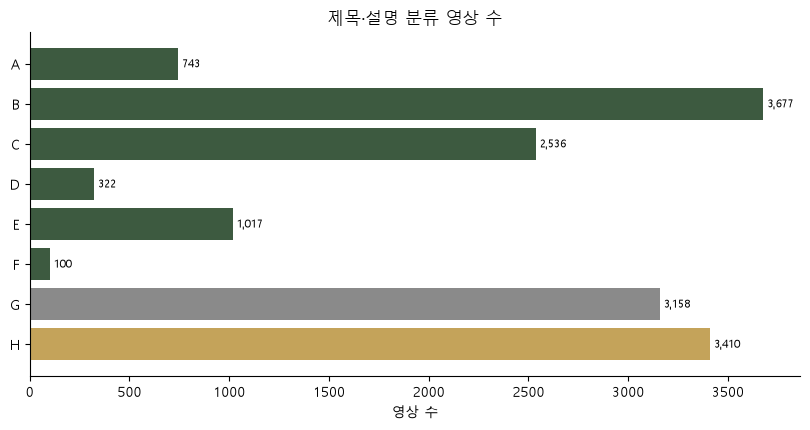

저장 youtube_analysis_video_class.csv 13,383행


In [3]:
PURPOSE_NAME = {
    "A": "작품·캐릭터 감상·장면 공유",
    "B": "개인 상품 관심·소비·소유·사용",
    "C": "팬 창작·꾸미기·제작물 공유",
    "D": "상품·거래·협찬·이벤트 안내",
    "E": "다른 인물·대상·팬덤 관련",
    "F": "콘텐츠 정보·번역·독자 교류",
    "G": "본문만으로 목적 판단 어려움",
    "H": "비한국어 본문",
}
PURPOSE_RULES = {
    "A": r"극장|영화|애니메이션|애니(?!메이트|마이)|본편|최신화|명장면|장면|풀영상|정주행|몰아보기|다시보기|원작|예고편|스포|전편",
    "B": r"키링|피규어|가챠|뽑기|굿즈|하울|언박|(?<!대)개봉|택배|내돈내산|내돈|소장|득템|스티커|문구|다이소|편의점|파우치|팝업|카페|성지|누이구루미|쿠지|제일복권|랜덤깡|굿즈깡|택배깡|마그넷|미니소|직구|도시락|포장영상|포장하기|인형(?!계|극|만들)",
    "C": r"인형계|상황극|팬아트|일러스트|그렸|그려봤|그리기|그림(?!책)|드로잉|만들기|만들어봤|꾸미|다꾸|점토|레진|뜨개|코바늘|커스텀|따라하|손그림|비즈",
    "D": r"판매|팝니다|삽니다|양도|나눔|교환|공구|공동구매|중고|협찬|유료광고|광고\s*포함|제공받|제공해주|이벤트|추첨|증정|당첨|입고|출시|예약판매",
    "E": r"콜라보|산리오|쿠로미|마이멜로디|폼폼푸린|시나모롤|헬로키티|포챠코|포켓몬|피카츄|스누피|리락쿠마|릴라쿠마|스밋코|짱구|도라에몽|잔망루피|몰랑이|귀멸|코난|주술회전|히로아카|농담곰|다마고치|캐릭캐릭|마법소녀|산나비|미쿠|피크민|유니클로",
    "F": r"번역|해석|한글화|한글자막|한국어\s*자막|단행본|원서|세계관|(?<!구)독자|연재|요약|스포일러",
}

title_text = video["post_title"].fillna("")
desc_text = video["description"].fillna("")
body_text = title_text + "\n" + desc_text
has_hangul = body_text.str.contains(r"[가-힣]", regex=True)

for code, pattern in PURPOSE_RULES.items():
    video[f"분류_{code}"] = has_hangul & body_text.str.contains(pattern, regex=True)
    found = body_text.str.findall(pattern)
    video[f"_hit_{code}"] = found.map(lambda words: ",".join(dict.fromkeys(words)))

video["분류_C"] = video["분류_C"] | (has_hangul & title_text.str.contains(r"더빙", regex=True))
dub_hit = title_text.str.findall(r"더빙")
def merge_hits(words, extra):
    parts = [part for part in words.split(",") if part] if words else []
    return ",".join(dict.fromkeys([*parts, *extra]))

video["_hit_C"] = [merge_hits(words, extra) for words, extra in zip(video["_hit_C"], dub_hit)]

purpose_hit = video[[f"분류_{code}" for code in "ABCDEF"]].any(axis=1)
video["분류_H"] = ~has_hangul
video["분류_G"] = has_hangul & ~purpose_hit

def purpose_codes(row):
    if row["분류_H"]:
        return "H"
    picked = [code for code in "ABCDEF" if row[f"분류_{code}"]]
    return "|".join(picked) if picked else "G"

def purpose_evidence(row):
    if row["분류_H"]:
        return "한글 없음"
    hits = [f"{code}:{row[f'_hit_{code}']}" for code in "ABCDEF" if row[f"분류_{code}"] and row[f"_hit_{code}"]]
    return " | ".join(hits) if hits else "해당 키워드 없음"

video["분류"] = video.apply(purpose_codes, axis=1)
video["분류명"] = video["분류"].map(
    lambda value: "|".join(PURPOSE_NAME[code] for code in value.split("|"))
)
video["분류_근거"] = video.apply(purpose_evidence, axis=1)
video = video.drop(columns=[f"_hit_{code}" for code in "ABCDEF"])

by_code = {code: video.loc[video[f"분류_{code}"]].copy() for code in "ABCDEFGH"}

summary = pd.DataFrame({
    "코드": list(PURPOSE_NAME),
    "분류": list(PURPOSE_NAME.values()),
    "영상수": [int(video[f"분류_{code}"].sum()) for code in PURPOSE_NAME],
})
summary["비율"] = (summary["영상수"] / len(video)).round(3)
display(summary)
print(f"A–F가 둘 이상인 영상 {int(video['분류'].str.contains('|', regex=False).sum()):,}건")
print(f"설명 결측 {int(video['description'].isna().sum()):,}건. 이 영상은 제목만으로 분류했다.")

for code in "ABCDEFGH":
    print(f"\n[{code}] {PURPOSE_NAME[code]} 예시")
    sample = by_code[code][["post_title", "분류", "분류_근거"]].head(5)
    display(sample)

fig, ax = plt.subplots(figsize=(8.2, 4.4))
colors = ["#c4a35a", "#8a8a8a", *["#3d5a40"] * 6]
bars = ax.barh(summary["코드"][::-1], summary["영상수"][::-1], color=colors)
ax.bar_label(bars, labels=[f"{int(v):,}" for v in summary["영상수"][::-1]], padding=3, fontsize=8)
ax.set_xlabel("영상 수")
ax.set_title("제목·설명 분류 영상 수")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

class_path = VIDEO_CSV.with_name("youtube_analysis_video_class.csv")
class_cols = ["post_id", "post_title", "year", "분류", "분류명", "분류_근거", *[f"분류_{code}" for code in "ABCDEFGH"]]
video[class_cols].to_csv(class_path, index=False, encoding="utf-8-sig")
print(f"저장 {class_path.name} {len(video):,}행")


### G 표본 100개의 화면 확인

키워드로 G가 된 3,158건에서 같은 확률로 100건을 뽑았다. 난수 씨앗은 `20261030`이다. 각 영상의 대표 화면과 제목을 보고, 그 영상의 주된 목적 하나를 적었다. 영상 전체를 재생한 것은 아니다. 쇼츠는 대표 화면이 내용인 경우가 많고, 끝 화면만 잡힌 경우는 제목을 함께 봤다.

비율은 이 100건의 결과다. 3,158건 전체로 그대로 옮기면 표본오차가 있다. 40% 안팎의 비율은 95% 구간이 대략 ±10%p다.


,코드,분류,영상수,비율
0,A,작품·캐릭터 감상·장면 공유,17,0.17
1,B,개인 상품 관심·소비·소유·사용,41,0.41
2,C,팬 창작·꾸미기·제작물 공유,17,0.17
3,D,상품·거래·협찬·이벤트 안내,2,0.02
4,E,다른 인물·대상·팬덤 관련,5,0.05
5,F,콘텐츠 정보·번역·독자 교류,2,0.02
6,G,화면을 봐도 목적 판단 어려움,16,0.16


A–F로 갈린 표본 84건
화면을 봐도 G로 남은 표본 16건


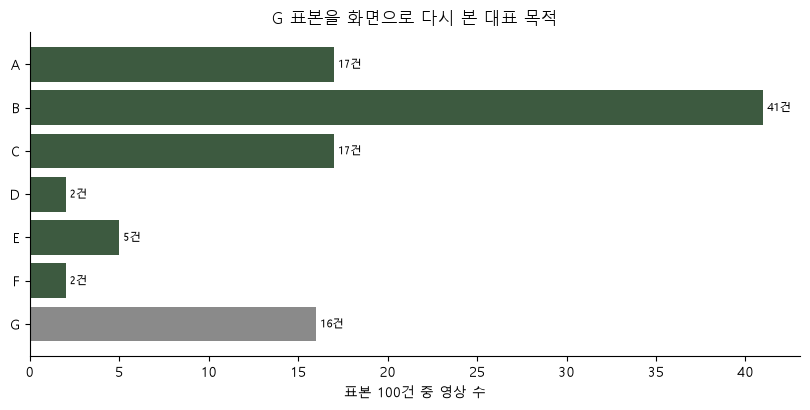

In [4]:
sample_path = VIDEO_CSV.with_name("youtube_g_sample_100.csv")
sample100 = pd.read_csv(sample_path, encoding="utf-8-sig")
order = list("ABCDEFG")
sample_summary = (
    sample100["표본분류"].value_counts()
    .reindex(order)
    .rename_axis("코드")
    .reset_index(name="영상수")
)
sample_summary["분류"] = sample_summary["코드"].map({
    "A": "작품·캐릭터 감상·장면 공유",
    "B": "개인 상품 관심·소비·소유·사용",
    "C": "팬 창작·꾸미기·제작물 공유",
    "D": "상품·거래·협찬·이벤트 안내",
    "E": "다른 인물·대상·팬덤 관련",
    "F": "콘텐츠 정보·번역·독자 교류",
    "G": "화면을 봐도 목적 판단 어려움",
})
sample_summary["비율"] = (sample_summary["영상수"] / len(sample100)).round(2)
display(sample_summary[["코드", "분류", "영상수", "비율"]])
print(f"A–F로 갈린 표본 {int(sample_summary.loc[sample_summary['코드'] != 'G', '영상수'].sum())}건")
print(f"화면을 봐도 G로 남은 표본 {int(sample_summary.loc[sample_summary['코드'] == 'G', '영상수'].sum())}건")

fig, ax = plt.subplots(figsize=(8.2, 4.2))
colors = ["#3d5a40"] * 6 + ["#8a8a8a"]
plot_df = sample_summary.iloc[::-1]
bars = ax.barh(plot_df["코드"], plot_df["영상수"], color=colors[::-1])
ax.bar_label(bars, labels=[f"{int(v)}건" for v in plot_df["영상수"]], padding=3, fontsize=8)
ax.set_xlabel("표본 100건 중 영상 수")
ax.set_title("G 표본을 화면으로 다시 본 대표 목적")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()
